(gallant_tauchen)=
```{raw} jupyter
<div id="qe-notebook-header" align="right" style="text-align:right;">
        <a href="https://quantecon.org/" title="quantecon.org">
                <img style="width:250px;display:inline;" width="250px" src="https://assets.quantecon.org/img/qe-menubar-logo.svg" alt="QuantEcon">
        </a>
</div>
```

# 应该匹配哪些矩？

```{contents} Contents
:depth: 2
```

## 概述

一些结构经济模型具有以下两个特性：

* 给定一个已知的参数向量，可以计算出均衡并对其进行模拟

* 无法用解析方式写出似然函数

我们可以求解"正问题"，它将一个参数向量映射为数据的概率分布。

我们不能使用最大似然法来求解"逆问题"，即将观测数据集映射为参数向量的估计。

拥有此类模型的研究者转向 {cite:t}`Hansen1982` 的广义矩方法，并通过模拟来计算矩 {cite}`McFadden1989,PakesPollard1989,DuffieSingleton1993`。

他们必须决定要匹配哪些矩。

A. Ronald Gallant 和 George Tauchen 在 {cite:t}`GallantTauchen1996` 中研究了这个问题。

他们提出了两个模型：

* 经济学家的**结构**模型，由参数向量 $\rho$ 索引，其似然函数无法写出

* 一个独立的、描述性的**辅助**模型，由参数向量 $\theta$ 索引，其似然函数可以写出并最大化

这两个参数向量通常维度不同，含义也总是不同。

* $\rho$ 指定了结构模型中主体的偏好、技术、约束集合及其他特征。经济学家想要了解 $\rho$。

* $\theta$ 总结观测数据。它的各分量不回答任何经济学问题。经济学家估计 $\theta$ 仅仅是作为估计 $\rho$ 的一个步骤。

|  | 结构模型 | 辅助模型 |
|---|---|---|
| 密度 | $p(y_t \mid x_t, \rho)$ | $f(y_t \mid x_t, \theta)$ |
| 参数 | $\rho \in \mathbb{R}^{k_\rho}$ | $\theta \in \mathbb{R}^{k_\theta}$ |
| 解释 | 经济学的 | 描述性的 |
| 似然 | 不可得 | 可得 |
| 角色 | 推断对象 | 矩条件的来源 |

这里 $x_t$ 收集了 $y_t$ 的滞后值，可能是全部历史。

在下面的随机波动率例子中，$\rho = (a, r_w, r_y)$ 控制一个潜在对数波动率过程，而 $\theta = (\mu, \omega, \alpha, \beta)$ 持有一个 GARCH(1,1) 模型的参数。

$\theta$ 中的任何分量都不对应于 $\rho$ 中的某个分量。

Gallant 和 Tauchen 的方法使用与辅助模型似然函数相关的**得分**作为 GMM 的矩向量。

他们对观测数据拟合一次 $\theta$。

然后他们选择 $\rho$，使得在从结构模型模拟出的数据中，在该拟合的 $\theta$ 处计算出的辅助得分的平均值尽可能接近零。

```{note}
{ref}`gt_why_score` 一节表明，得分矩条件是库尔贝克-莱布勒散度的负梯度。
{doc}`divergence_measures` 和 {doc}`likelihood_ratio_process` 研究了 KL 散度的性质。
```

Gallant 和 Tauchen 证明，如果辅助模型嵌套了结构模型，他们的估计量与最大似然法一样有效。

他们论证道，如果辅助模型很好地逼近了数据的分布，该估计量几乎同样有效。

实践者称他们的方法为**矩的高效方法**，或 EMM。

{cite:t}`GallantTauchen2010` 对该方法及其应用进行了综述。

让我们从一些导入开始。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numba import jit
from scipy.optimize import minimize
from scipy.stats import chi2

## 估计问题

结构模型是观测过程 $\{y_t\}$ 的一系列概率密度，

$$
p(y_t \mid x_t, \rho), \qquad \rho \in \mathcal{R} \subset \mathbb{R}^{k_\rho} ,
$$

其中 $x_t$ 收集了该模型所依据的任何条件，通常是 $y_t$ 的滞后值。

我们称 $\rho$ 为**结构参数向量**。

自然界从 $\rho^0$ 生成了观测数据 $\{\tilde y_t, \tilde x_t\}_{t=1}^n$。

波浪号标记观测数据及由其计算出的统计量。

帽子符号标记模拟数据以及最终的估计量 $\hat\rho_n$。

我们对结构模型做两个假设。

模拟是可行的：给定 $\rho$，我们可以生成一个长的人工序列 $\{\hat y_\tau, \hat x_\tau\}_{\tau=1}^N$。

似然不可得：$\prod_t p(\tilde y_t \mid \tilde x_t, \rho)$ 没有我们能够计算和最大化的表达式。

Gallant 和 Tauchen 将平稳马尔可夫结构模型作为主要情形。

这样一次长的模拟就足以计算模型下的任何期望。

他们的论文还涵盖了独立的截面数据以及运动规律依赖于 $t$ 的过程。

## 辅助模型及其得分

辅助模型是同一观测过程的第二个密度序列，

$$
f(y_t \mid x_t, \theta), \qquad \theta \in \Theta \subset \mathbb{R}^{k_\theta} .
$$

我们称 $\theta$ 为**辅助参数向量**。

Gallant 和 Tauchen 把辅助模型称为**得分生成器**。

两个特性使辅助模型变得有用。

它的密度有解析表达式，因此我们可以写出其似然并对其求导。

它能很好地描述数据。

第一个特性是必需的。

一致性只要求得分能识别 $\rho$，{ref}`gt_ex1` 和 {ref}`gt_ex3` 对此进行了说明。

{ref}`gt_choosing` 一节解释了良好拟合能带来什么。

资产收益率的 GARCH 模型、向量自回归以及条件密度的埃尔米特级数展开都符合条件。

辅助模型的**得分**是其对数密度相对于自身参数的导数，

$$
s(y, x, \theta) = \frac{\partial}{\partial \theta} \ln f(y \mid x, \theta) .
$$

得分是一个 $k_\theta \times 1$ 向量，我们可以在任何 $(y, x, \theta)$ 处计算它。

## 估计量

该估计量分三步进行。

**第一步：投影。** 通过拟最大似然将辅助模型拟合到观测数据，

$$
\tilde \theta_n = \arg\max_{\theta \in \Theta} \frac{1}{n} \sum_{t=1}^n \ln f(\tilde y_t \mid \tilde x_t, \theta) .
$$

这一步仅使用数据和辅助模型，因此它只发生一次，在估计任何结构参数之前。

**第二步：通过模拟求矩。** 将矩函数 $m(\rho, \theta)$ 定义为辅助得分*在结构模型下*的期望，

```{math}
:label: eq:gt_mfun

m(\rho, \theta) = \int \! \! \int s(y, x, \theta) \, p(y \mid x, \rho) \, dy \, p(x \mid \rho) \, dx ,
```

其中 $p(x \mid \rho)$ 是结构模型下 $x_t$ 的平稳密度。

一次长模拟在 $\theta = \tilde\theta_n$ 处逼近该二重积分，

```{math}
:label: eq:gt_moment

m(\rho, \tilde \theta_n) \approx \frac{1}{N} \sum_{\tau=1}^{N} s(\hat y_\tau, \hat x_\tau, \tilde \theta_n)
```

{eq}`eq:gt_moment` 式的右边是在 $\rho$ 处从结构模型进行一次长模拟中对辅助得分求平均。

每次计算都需要一次模拟，而不需要优化。

**第三步：GMM。** 通过使矩向量尽可能接近零（在 GMM 度量所允许的范围内）来估计 $\rho$，

```{math}
:label: eq:gt_estimator

\hat \rho_n = \arg\min_{\rho \in \mathcal{R}} \;
   m(\rho, \tilde \theta_n)^\top \, (\tilde{\mathcal{I}}_n)^{-1} \, m(\rho, \tilde \theta_n) ,
```

其中

```{math}
:label: eq:gt_weight

\tilde{\mathcal{I}}_n = \frac{1}{n} \sum_{t=1}^n
   s(\tilde y_t, \tilde x_t, \tilde \theta_n) \, s(\tilde y_t, \tilde x_t, \tilde \theta_n)^\top .
```

{eq}`eq:gt_weight` 式中的权重矩阵是数据处辅助得分的外积。

它估计 $\mathcal{I}^0$，即 $n^{-1/2} \sum_{t=1}^n s(\tilde y_t, \tilde x_t, \theta^0)$ 的渐近方差，其中 $\theta^0$ 是 $\tilde\theta_n$ 的概率极限。

它仅依赖于辅助模型和数据。

当得分是序列不相关的时，外积是一个有效估计。

能正确描述数据条件分布的辅助模型会产生序列不相关的得分。

当辅助模型正确地指定了条件均值和方差时，高斯拟最大似然得分也是序列不相关的 {cite}`BollerslevWooldridge1992`。

否则，Gallant 和 Tauchen 建议使用带有 Parzen 权重的异方差与自相关一致估计量 {cite}`Gallant1987`，并引用 {cite:t}`Andrews1991` 的其他替代方案。

{ref}`gt_ex4` 展示了当得分序列相关时，外积会在多大程度上低估 $\mathcal{I}^0$。

研究者在对 $\rho$ 进行搜索之前，只需计算其中一种估计一次。

GMM 通常需要结构参数的初步估计来构建有效的权重矩阵，而有了这两种估计中的任何一种，这一要求就消失了。

识别的阶条件是 $k_\theta \ge k_\rho$。

阶条件是必要但不充分的，{ref}`gt_ex3` 构造了一个失败的例子。

(gt_why_score)=
## 为什么得分是正确的匹配对象

{doc}`divergence_measures` 表明，最大似然法最小化了数据的经验分布到参数化模型的 KL 散度。

第一步通过最小化 KL 散度将数据投影到辅助族上。

对每个 $\rho$，定义**伪真值**

$$
\theta^0(\rho) = \arg\min_{\theta \in \Theta} \;
    D_{KL}\bigl( p(\cdot \mid \rho) \, \| \, f(\cdot \mid \theta) \bigr) ,
$$

即辅助族中最接近 $\rho$ 处结构模型的点 {cite}`White1982` [^gt_cond]。

[^gt_cond]: 这里 $p(\cdot \mid \rho)$ 和 $f(\cdot \mid \theta)$ 是给定 $x_t$ 时 $y_t$ 的条件密度。该散度对 $\int p(y \mid x, \rho) \ln \bigl[ p(y \mid x, \rho) / f(y \mid x, \theta) \bigr] \, dy$ 在 $p(x \mid \rho)$ 的平稳密度上取平均。

函数 $\theta^0(\cdot)$ 将结构参数映射为辅助参数。

随着 $n$ 增大，$\tilde\theta_n$ 收敛到 $\theta^0 = \theta^0(\rho^0)$。

现在对该散度关于 $\theta$ 求导：

```{math}
:label: eq:gt_kl

\frac{\partial}{\partial \theta} D_{KL}\bigl( p(\cdot \mid \rho) \, \| \, f(\cdot \mid \theta) \bigr)
 = \frac{\partial}{\partial \theta} \left[ \int p \ln p - \int p \ln f_\theta \right]
 = - \, m(\rho, \theta)
```

{eq}`eq:gt_mfun` 式的矩函数是库尔贝克-莱布勒散度的负梯度。

令 $m(\rho, \theta) = 0$ 陈述了 KL 投影的一阶条件。

{eq}`eq:gt_estimator` 式的估计量搜索这样一个结构参数：它在辅助族上的 KL 投影落在数据的投影所落之处，或者当 $k_\theta > k_\rho$ 时在 GMM 度量所允许的范围内尽可能接近。

这种解读说明了为什么结构模型不必嵌套在辅助模型内部。

在 $\rho = \rho^0$ 处，结构模型生成了数据，这两个投影重合，并且 $m(\rho^0, \theta^0) = 0$。

{ref}`gt_ex1` 要求你验证这一推理链。

## 效率

一致性和渐近正态性在较弱的正则条件下成立，

$$
\sqrt{n} \, (\hat \rho_n - \rho^0) \to N
   \Bigl( 0, \bigl[ (M^0)^\top (\mathcal{I}^0)^{-1} M^0 \bigr]^{-1} \Bigr) ,
\qquad M^0 = \frac{\partial}{\partial \rho^\top} m(\rho^0, \theta^0) ,
$$

这是 {cite:t}`GallantTauchen1996` 中的定理 1。

这里 $\mathcal{I}^0$ 是辅助得分的方差，{eq}`eq:gt_weight` 式中的 $\tilde{\mathcal{I}}_n$ 对其进行估计。

该公式假设权重矩阵收敛到 $(\mathcal{I}^0)^{-1}$，正如当 $\tilde{\mathcal{I}}_n$ 一致地估计 $\mathcal{I}^0$ 时 $(\tilde{\mathcal{I}}_n)^{-1}$ 所做的那样。

对于任何其他极限权重矩阵 $W$，渐近方差采取三明治形式

$$
\bigl[ (M^0)^\top W M^0 \bigr]^{-1} (M^0)^\top W \, \mathcal{I}^0 \, W M^0 \bigl[ (M^0)^\top W M^0 \bigr]^{-1} .
$$

{ref}`gt_ex4` 用到了它。

Gallant 和 Tauchen 假设 $N$ 足够大，以使模拟误差可以忽略不计，因此该公式将 $m$ 视为精确计算的。

长度为 $N$ 的模拟会给 $m$ 增加独立噪声，并将 $\sqrt{n}\, m$（从而 $\hat\rho_n$）的渐近方差乘以 $1 + n/N$。

当一个二次连续可微的映射 $g$ 将结构参数带入辅助参数时，Gallant 和 Tauchen 称结构模型在辅助模型内被**光滑嵌入**，

$$
p(y \mid x, \rho) = f\bigl( y \mid x, g(\rho) \bigr)
   \qquad \text{对所有接近 } \rho^0 \text{ 的 } \rho .
$$

光滑嵌入表明辅助模型嵌套了结构模型。

一般来说，$p(\cdot \mid \rho)$ 位于辅助族之外，没有任何 $g$ 满足这个等式。

函数 $\theta^0(\rho)$ 总是存在的。

在光滑嵌入下，$\theta^0(\rho) = g(\rho)$。

记 $G^0 = \partial g(\rho^0) / \partial \rho^\top$。

他们的定理 2 指出，光滑嵌入意味着

$$
\sqrt{n} \, (\hat \rho_n - \rho^0) \to N
   \Bigl( 0, \bigl[ (G^0)^\top \mathcal{I}^0 G^0 \bigr]^{-1} \Bigr) ,
$$

这正是 $\rho$ 的最大似然估计量的渐近分布。

证明的关键在于恒等式 $M^0 = \mathcal{I}^0 G^0$，它将 GMM 方差转换为最大似然方差。

该估计量在不需要结构似然的情况下达到了最大似然效率。

光滑嵌入是一个很强的假设，而一致性和渐近正态性并不需要它。

Gallant 和 Tauchen 论证道，一个在不嵌套结构模型的情况下很好地逼近数据分布的辅助模型，会产生一个几乎完全有效的估计量。

Gallant 和 Tauchen 将此解读为关于如何选择辅助模型的指示：让它很好地拟合数据。

## 与匹配辅助参数的比较

间接推断命名了通过辅助模型比较观测数据与模拟数据的那一类估计量。

{cite:t}`GourierouxMonfortRenault1993` 和 {cite:t}`Smith1993` 匹配辅助参数。

{cite:t}`GourierouxMonfortRenault1993` 称 $\theta^0(\rho)$ 为**约束函数**。

他们的估计量是

$$
\hat \rho_{II} = \arg\min_{\rho} \;
  \bigl[ \tilde\theta_n - \theta^0(\rho) \bigr]^\top \, \Omega \, \bigl[ \tilde\theta_n - \theta^0(\rho) \bigr]
$$

其中 $\Omega$ 为权重矩阵。

在光滑嵌入下 $\theta^0 = g$，选择 $\Omega = \mathcal{I}^0$ 会得到最小卡方估计量，该估计量与最大似然法一样有效。

每当结构似然不可得时，约束函数也就不可得，因此实践者用对 $H$ 个模拟数据集计算出的辅助估计的平均值来代替 $\theta^0(\rho)$。

这种替代代价高昂。

每个试探性的 $\rho$ 值都需要对辅助似然进行 $H$ 次独立的最大化，每个模拟数据集一次。

基于得分的估计量只需要对辅助似然进行一次最大化，即在第一步中进行，且永不重复。

在适当选择权重矩阵的情况下，基于参数的估计量与基于得分的估计量是渐近等价的 {cite}`GourierouxMonfortRenault1993`。

匹配得分的优势在于计算量。

有限样本的表现可能不同。

{cite:t}`DuffeeStanton2008` 研究了高度持续的高斯自回归，发现得分匹配得出的置信区间比参数匹配的更宽，但覆盖真值的可能性更低。

他们将这一问题追溯到总体方差在得分矩条件中所起的重要作用。

(gt_choosing)=
## 选择得分生成器

一个已知能准确描述数据的模型应被用作辅助模型。

如果缺乏这样的模型，Gallant 和 Tauchen 推荐两个通用族。

{cite:t}`GallantNychka1987` 和 {cite:t}`GallantTauchen1989` 的**半非参数**（SNP）密度将一个高斯密度乘以一个系数依赖于滞后值的埃尔米特多项式的平方。

调节参数可以嵌套独立同分布高斯、高斯向量自回归、高斯 ARCH 和 GARCH，以及完全非线性的非参数设定，因此通过设定搜索可以从数据中选出辅助模型 {cite}`GallantTauchen2010`。

**神经网络**得分可以逼近任何非线性自回归，包括确定性混沌。

这两个族都是级数展开，因此增加项数会使逼近误差趋于零。

增加项数也会使得分的条件均值趋于零，因此得分接近鞅差分。

此时，{eq}`eq:gt_weight` 式的外积能准确估计 $\mathcal{I}^0$，权重矩阵也无需对序列相关进行修正。

因此，良好的拟合带来两个好处：接近有效性以及有效的外积权重矩阵。

{ref}`gt_ex4` 展示了当得分生成器缺乏第二个好处时会发生什么。

项数的多少决定了偏差与方差之间的权衡。

更多的项会减小辅助模型的逼近误差，并增大 $\tilde\theta_n$ 的抽样方差。

Gallant 和 Tauchen 警告不要使用过多的项，然后又声称标准渐近理论适用。

## 第一个例子：AR(2) 中嵌套的 AR(1)

有一个例子我们*可以*计算最大似然估计量，它可以让我们检验定理 2。

将结构模型设为一个高斯一阶自回归，

$$
y_t = \rho_1 y_{t-1} + \sigma \epsilon_t , \qquad \epsilon_t \sim N(0,1) ,
$$

其中 $\rho = (\rho_1, \sigma)^\top$。

将辅助模型设为一个高斯二阶自回归，

$$
y_t = \theta_1 y_{t-1} + \theta_2 y_{t-2} + \varsigma e_t , \qquad e_t \sim N(0,1) ,
$$

其中 $\theta = (\theta_1, \theta_2, \varsigma)^\top$。

AR(2) 通过 $g(\rho_1, \sigma) = (\rho_1, 0, \sigma)$ 嵌套了 AR(1)，因此结构模型被光滑嵌入，且 $k_\theta = 3$ 超过了 $k_\rho = 2$。

分量 $\theta_1$ 与 $\rho_1$ 只有因为 AR(2) 嵌套了 AR(1) 才共享一种解释。

定理 2 预测，我们的估计量与最大似然估计量具有相同的渐近分布，仅相差一个模拟因子 $1 + n/N$。

记 $u_t = y_t - \theta_1 y_{t-1} - \theta_2 y_{t-2}$，辅助得分为

$$
s(y_t, x_t, \theta) =
\begin{bmatrix} u_t y_{t-1} / \varsigma^2 \\ u_t y_{t-2} / \varsigma^2 \\ -1/\varsigma + u_t^2 / \varsigma^3 \end{bmatrix} .
$$

In [2]:
@jit(nopython=True)
def simulate_ar1(ρ1, σ, ε):
    "Simulate the structural AR(1) from a fixed array of shocks ε."
    n = ε.size
    y = np.empty(n)
    y[0] = σ * ε[0] / np.sqrt(1 - ρ1**2)
    for t in range(1, n):
        y[t] = ρ1 * y[t-1] + σ * ε[t]
    return y

def ar2_scores(θ, y):
    "Per-observation scores of the Gaussian AR(2) auxiliary model."
    θ1, θ2, ς = θ
    yt, y1, y2 = y[2:], y[1:-1], y[:-2]
    u = yt - θ1 * y1 - θ2 * y2
    return np.column_stack([u * y1 / ς**2, u * y2 / ς**2, -1/ς + u**2 / ς**3])

def ar2_qmle(y):
    "Quasi-maximum likelihood estimates of the AR(2), available in closed form."
    X = np.column_stack([y[1:-1], y[:-2]])
    b = np.linalg.lstsq(X, y[2:], rcond=None)[0]
    ς = np.sqrt(np.mean((y[2:] - X @ b)**2))
    return np.array([b[0], b[1], ς])

让我们从结构模型生成数据，并计算条件最大似然估计量，对于这个模型来说该估计量就是最小二乘法。

In [3]:
rng = np.random.default_rng(0)
T, ρ1_0, σ_0 = 1000, 0.8, 1.0
y_data = simulate_ar1(ρ1_0, σ_0, rng.standard_normal(T))

X1 = y_data[:-1]
ρ1_mle = float(X1 @ y_data[1:] / (X1 @ X1))
σ_mle = float(np.sqrt(np.mean((y_data[1:] - ρ1_mle * X1)**2)))
print(f"maximum likelihood:  ρ1 = {ρ1_mle:.4f}   σ = {σ_mle:.4f}")

maximum likelihood:  ρ1 = 0.8022   σ = 0.9784


第一步拟合辅助模型并构造权重矩阵。

In [4]:
θ_tilde = ar2_qmle(y_data)
S = ar2_scores(θ_tilde, y_data)
I_tilde = S.T @ S / S.shape[0]
W = np.linalg.inv(I_tilde)

print(f"auxiliary QMLE: θ1 = {θ_tilde[0]:.4f}, θ2 = {θ_tilde[1]:.4f}, ς = {θ_tilde[2]:.4f}")

auxiliary QMLE: θ1 = 0.8083, θ2 = -0.0075, ς = 0.9789


$\theta_2$ 的估计值接近于零，正如嵌套映射 $g$ 所预期的那样。

第二步和第三步进行模拟和最小化。

我们一次性抽取冲击 $\epsilon$，并在每个试探性的 $\rho$ 值处重复使用它们。

我们称其为**公共随机数**，下面的图展示了它们对目标函数的影响。

In [5]:
N = 20_000
ε_sim = rng.standard_normal(N)      # common random numbers

def moments_ar1(ρ):
    "Expectation under the structural model of the auxiliary score."
    y_sim = simulate_ar1(ρ[0], ρ[1], ε_sim)
    return ar2_scores(θ_tilde, y_sim).mean(axis=0)

def criterion_ar1(ρ):
    if not (abs(ρ[0]) < 0.999 and ρ[1] > 1e-6):
        return 1e10
    m = moments_ar1(ρ)
    return float(m @ W @ m)

res = minimize(criterion_ar1, np.array([0.5, 1.5]), method='Nelder-Mead',
               options=dict(xatol=1e-6, fatol=1e-12, maxiter=2000))

print(f"true values:         ρ1 = {ρ1_0:.4f}   σ = {σ_0:.4f}")
print(f"maximum likelihood:  ρ1 = {ρ1_mle:.4f}   σ = {σ_mle:.4f}")
print(f"score matching:      ρ1 = {res.x[0]:.4f}   σ = {res.x[1]:.4f}")

true values:         ρ1 = 0.8000   σ = 1.0000
maximum likelihood:  ρ1 = 0.8022   σ = 0.9784
score matching:      ρ1 = 0.8009   σ = 0.9830


这两组估计值几乎重合，仅在小数点第三位有所不同。

下图在 $\sigma$ 固定为其估计值的情况下，在 $\rho_1$ 值的网格上计算目标函数。

一条曲线使用公共随机数 `ε_sim`，另一条曲线在每个网格点都抽取新的冲击。

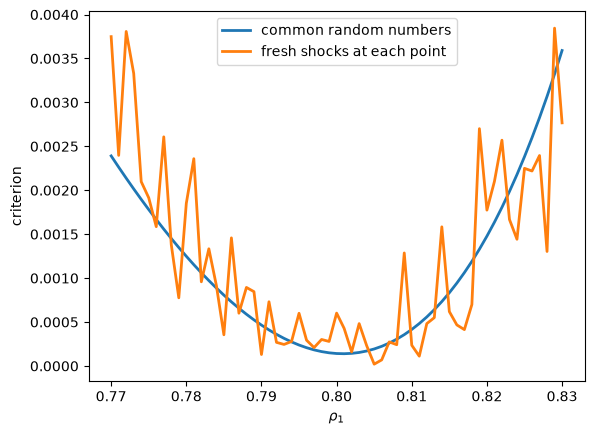

In [6]:
rng_fresh = np.random.default_rng(1)
ρ1_grid = np.linspace(0.77, 0.83, 61)
σ_hat = res.x[1]

def criterion_fresh(ρ):
    "The criterion with a fresh draw of shocks at each evaluation."
    y_sim = simulate_ar1(ρ[0], ρ[1], rng_fresh.standard_normal(N))
    m = ar2_scores(θ_tilde, y_sim).mean(axis=0)
    return float(m @ W @ m)

crn = [criterion_ar1(np.array([r1, σ_hat])) for r1 in ρ1_grid]
fresh = [criterion_fresh(np.array([r1, σ_hat])) for r1 in ρ1_grid]

fig, ax = plt.subplots()
ax.plot(ρ1_grid, crn, lw=2, label='common random numbers')
ax.plot(ρ1_grid, fresh, lw=2, label='fresh shocks at each point')
ax.set_xlabel(r'$\rho_1$')
ax.set_ylabel('criterion')
ax.legend()
plt.show()

新的冲击使目标函数变得锯齿状，存在许多局部极小值。

公共随机数使目标函数成为 $\rho_1$ 的光滑函数，只有一个最小值。

被最小化的目标函数检验了结构模型对辅助模型施加的 $k_\theta - k_\rho = 1$ 个过度识别约束。

在正确设定下，$n$ 乘以最小化目标函数，再除以模拟因子 $1 + n/N$，渐近服从 $\chi^2(k_\theta - k_\rho)$ 分布 [^gt_sim]。

代码将样本量 $n$ 写为 `T`。

[^gt_sim]: 在 AR(1) 例子中该因子为 $1.05$，在随机波动率例子中为 $1.04$。当 $N$ 相对于 $n$ 不是很大时，这一点就很重要。

In [7]:
J = T * criterion_ar1(res.x) / (1 + T / N)
df = 3 - 2
print(f"J = {J:.3f},  χ²({df}) 5% critical value = {chi2.ppf(0.95, df):.3f}")

J = 0.133,  χ²(1) 5% critical value = 3.841


定理 1 给出了标准误。

我们通过对模拟出的矩向量进行中心差分来计算 $M^0$，公共随机数使其在 $\rho$ 中光滑，并将方差乘以模拟因子 $1 + n/N$。

对于 AR(1) 模型，最大似然标准误对 $\rho_1$ 为 $\sqrt{(1 - \rho_1^2)/n}$，对 $\sigma$ 为 $\sigma / \sqrt{2n}$。

In [8]:
def jacobian(moments, ρ, h=1e-4):
    "Central-difference Jacobian of a moment function with respect to ρ."
    cols = []
    for j in range(ρ.size):
        e = np.zeros(ρ.size)
        e[j] = h * max(1.0, abs(ρ[j]))
        cols.append((moments(ρ + e) - moments(ρ - e)) / (2 * e[j]))
    return np.column_stack(cols)

def std_errors(moments, ρ, W, n, N):
    "Asymptotic standard errors from Theorem 1, including the simulation factor."
    M = jacobian(moments, ρ)
    V = np.linalg.inv(M.T @ W @ M) * (1 + n / N) / n
    return np.sqrt(np.diag(V))

se_emm = std_errors(moments_ar1, res.x, W, T, N)
se_mle = np.array([np.sqrt((1 - ρ1_mle**2) / T), σ_mle / np.sqrt(2 * T)])

print(f"{'':20}{'se ρ1':>10}{'se σ':>10}")
print(f"{'maximum likelihood':20}{se_mle[0]:10.4f}{se_mle[1]:10.4f}")
print(f"{'score matching':20}{se_emm[0]:10.4f}{se_emm[1]:10.4f}")

e_data = y_data[1:] - ρ1_mle * y_data[:-1]
kurt_e = ((e_data - e_data.mean())**4).mean() / e_data.var()**2
print(f"\nkurtosis of the residuals = {kurt_e:.2f}")

                         se ρ1      se σ
maximum likelihood      0.0189    0.0219
score matching          0.0188    0.0241

kurtosis of the residuals = 3.29


$\rho_1$ 的两个标准误在小数点后三位上一致。

$\sigma$ 的得分匹配标准误比最大似然标准误大约 10%。

模拟因子 $1 + n/N = 1.05$ 解释了大约 2.5% 的差异。

权重矩阵 $\tilde{\mathcal{I}}_n$ 解释了剩下的部分：它从残差的样本四阶矩估计 $\sigma$ 得分的方差，而残差的峰度在这个样本中为 3.3，在总体中为 3。

{ref}`gt_ex2` 要求你比较两个估计量的抽样分布。

## 第二个例子：随机波动率

现在我们转向一个似然函数不可解的模型。

{cite:t}`GallantTauchen1996` 的第 4.2 节讨论了一个随机波动率模型，其均值方程还包含一个截距项和一个滞后收益率项。

我们舍去这两项，研究

$$
\begin{aligned}
y_t &= \exp(w_t) \, r_y \, z_t , \\
w_t &= a \, w_{t-1} + r_w \, \eta_t ,
\end{aligned}
$$

其中 $z_t$ 和 $\eta_t$ 是独立的标准正态分布随机变量，$\rho = (a, r_w, r_y)^\top$。

观测到的收益率 $y_t$ 的波动率为 $\exp(w_t) r_y$，由一个潜在自回归 $w_t$ 驱动。

写出 $\{y_t\}_{t=1}^n$ 的似然需要将潜在波动率路径从一个 $n$ 维积分中积掉，

$$
p(y_1, \ldots, y_n \mid \rho) = \int \cdots \int
   \prod_{t=1}^n \phi\bigl( y_t ; 0, e^{2w_t} r_y^2 \bigr) \, p(w_1, \ldots, w_n \mid a, r_w) \,
   dw_1 \cdots dw_n ,
$$

没有任何解析表达式能计算出它。

模拟该模型只需要两行代码。

该模型会产生厚尾和持续性波动率。

{cite:t}`GallantHsiehTauchen1997` 使用 SNP 得分生成器，将完整模型及其扩展拟合到标准普尔综合指数的 16,127 个日度观测数据。

{cite:t}`GallantTauchen1996` 第 4.1 节指出，ARCH 和 GARCH 模型能很好地拟合收益率数据。

我们选择高斯 GARCH(1,1) 作为辅助模型，

$$
y_t = \mu + u_t , \qquad u_t = \sigma_t \nu_t , \qquad
\sigma_t^2 = \omega + \alpha u_{t-1}^2 + \beta \sigma_{t-1}^2 ,
$$

其中 $\theta = (\mu, \omega, \alpha, \beta)^\top$，$\nu_t \sim N(0,1)$。

GARCH 条件密度通过 $\sigma_t^2$ 的递归式依赖于 $y_t$ 的全部过去，因此这里 $x_t$ 是整个历史。

Gallant 和 Tauchen 称这样的得分生成器为非马尔可夫的。

结构参数 $(a, r_w, r_y)$ 描述了一个潜在对数波动率过程；辅助参数 $(\mu, \omega, \alpha, \beta)$ 描述了观测收益率中的条件方差递归。

辅助模型不需要任何经济学解释。

它的凭证就是对数据的良好拟合。

我们对 GARCH 对数密度进行数值求导。

数值求导保持了方法的通用性：辅助模型只需支持对其对数似然的计算即可。

代码在无约束坐标 $(\mu, \log \omega, \operatorname{logit} \alpha, \operatorname{logit} \beta)$ 中拟合 GARCH 模型。

得分、权重矩阵和矩向量都指的是那些坐标。

重新参数化既不会改变 $\hat\rho_n$ 也不会改变检验统计量。

它将得分乘以一个固定的可逆矩阵，而目标函数 {eq}`eq:gt_estimator` 对该变换是不变的。

In [9]:
@jit(nopython=True)
def simulate_sv(a, r_w, r_y, z, η):
    "Simulate the structural stochastic volatility model."
    n = z.size
    y = np.empty(n)
    w = r_w * η[0] / np.sqrt(1.0 - a * a)
    y[0] = np.exp(w) * r_y * z[0]
    for t in range(1, n):
        w = a * w + r_w * η[t]
        y[t] = np.exp(w) * r_y * z[t]
    return y

@jit(nopython=True)
def garch_ll(μ, ω, α, β, y):
    "Per-observation log densities of the Gaussian GARCH(1,1) auxiliary model."
    n = y.size
    ll = np.empty(n)
    s2 = ω / max(1e-8, 1.0 - α - β)
    for t in range(n):
        u = y[t] - μ
        ll[t] = -0.5 * (np.log(2 * np.pi) + np.log(s2) + u * u / s2)
        s2 = ω + α * u * u + β * s2
    return ll

def unpack(θ):
    "Map unconstrained parameters to ω > 0 and α, β in (0, 1)."
    μ, lω, lα, lβ = θ
    return μ, np.exp(lω), 1 / (1 + np.exp(-lα)), 1 / (1 + np.exp(-lβ))

def garch_negll(θ, y):
    μ, ω, α, β = unpack(θ)
    if α + β > 0.999:
        return 1e10
    return -garch_ll(μ, ω, α, β, y).sum()

def garch_scores(θ, y):
    "Per-observation auxiliary scores by central differences."
    p, n = θ.size, y.size
    S = np.empty((n, p))
    for j in range(p):
        h = 1e-5 * max(1.0, abs(θ[j]))
        θp, θm = θ.copy(), θ.copy()
        θp[j] += h
        θm[j] -= h
        S[:, j] = (garch_ll(*unpack(θp), y) - garch_ll(*unpack(θm), y)) / (2 * h)
    return S

第 4.2 节没有报告参数值，因此我们自行选择。

让我们从结构模型生成一条长的收益率序列。

In [10]:
rng = np.random.default_rng(5)
T = 2000
a_0, r_w0, r_y0 = 0.80, 0.20, 0.65
y_sv = simulate_sv(a_0, r_w0, r_y0, rng.standard_normal(T), rng.standard_normal(T))

kurt = ((y_sv - y_sv.mean())**4).mean() / y_sv.var()**2
print(f"standard deviation = {y_sv.std():.3f},  kurtosis = {kurt:.2f}")

standard deviation = 0.738,  kurtosis = 3.93


在这些参数值下，$y_t$ 的总体峰度为 $3 \exp\bigl( 4 r_w^2 / (1 - a^2) \bigr) = 4.7$，高于高斯分布的 3。

样本峰度低估了它，正如重尾序列的样本峰度常常会做的那样。

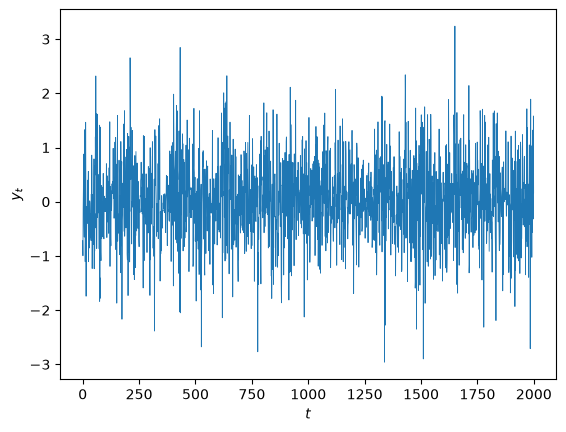

In [11]:
fig, ax = plt.subplots()
ax.plot(y_sv, lw=0.6)
ax.set_xlabel('$t$')
ax.set_ylabel('$y_t$')
plt.show()

第一步将 GARCH 辅助模型拟合到这些数据。

In [12]:
θ_start = np.array([0.0, np.log(0.05), -2.0, 1.5])
r = minimize(garch_negll, θ_start, args=(y_sv,), method='Nelder-Mead',
             options=dict(maxiter=8000, xatol=1e-8, fatol=1e-8))
θ_sv = r.x
μ_h, ω_h, α_h, β_h = unpack(θ_sv)
print(f"auxiliary GARCH QMLE: μ = {μ_h:.4f}, ω = {ω_h:.4f}, "
      f"α = {α_h:.4f}, β = {β_h:.4f}   (α + β = {α_h + β_h:.4f})")

S_sv = garch_scores(θ_sv, y_sv)
W_sv = np.linalg.inv(S_sv.T @ S_sv / T)

auxiliary GARCH QMLE: μ = 0.0150, ω = 0.0922, α = 0.1209, β = 0.7127   (α + β = 0.8337)


$\alpha + \beta$ 为 0.83，记录了辅助模型从数据中读出的波动率持续性。

第二步和第三步估计三个结构参数。

我们在无约束坐标上进行搜索，并在整个过程中重复使用一对冲击数组。

In [13]:
N = 50_000
z_sim, η_sim = rng.standard_normal(N), rng.standard_normal(N)

def moments_sv(ρ):
    y_s = simulate_sv(ρ[0], ρ[1], ρ[2], z_sim, η_sim)
    return garch_scores(θ_sv, y_s).mean(axis=0)

def to_ρ(u):
    "Map unconstrained coordinates to a in (0,1) and r_w, r_y > 0."
    return np.array([1 / (1 + np.exp(-u[0])), np.exp(u[1]), np.exp(u[2])])

def criterion_sv(u):
    if np.max(np.abs(u)) > 25:
        return 1e10
    m = moments_sv(to_ρ(u))
    return float(m @ W_sv @ m)

u_0 = np.array([np.log(0.6 / 0.4), np.log(0.3), np.log(0.5)])
res_sv = minimize(criterion_sv, u_0, method='Nelder-Mead',
                  options=dict(maxiter=400, xatol=1e-4, fatol=1e-10))
ρ_hat = to_ρ(res_sv.x)

定理 1 给出了标准误。

In [14]:
se_sv = std_errors(moments_sv, ρ_hat, W_sv, T, N)

print(f"{'':17}{'a':>9}{'r_w':>9}{'r_y':>9}")
print(f"{'true values':17}{a_0:9.4f}{r_w0:9.4f}{r_y0:9.4f}")
print(f"{'score matching':17}" + "".join(f"{x:9.4f}" for x in ρ_hat))
print(f"{'standard errors':17}" + "".join(f"{x:9.4f}" for x in se_sv))

                         a      r_w      r_y
true values         0.8000   0.2000   0.6500
score matching      0.8447   0.1794   0.6700
standard errors     0.0404   0.0372   0.0244


该估计量定位出一个我们从未写出其似然函数的模型的全部三个参数。

每一个估计值都落在其真值大约一个标准误之内。

数据对标度 $r_y$ 的估计最为精确。

## 检验结构模型

辅助模型有四个参数，结构模型有三个参数，因此还剩下一个过度识别约束有待检验。

In [15]:
J_sv = T * criterion_sv(res_sv.x) / (1 + T / N)
df_sv = 4 - 3
print(f"J = {J_sv:.3f},  χ²({df_sv}) 5% critical value = {chi2.ppf(0.95, df_sv):.3f}")

J = 0.606,  χ²(1) 5% critical value = 3.841


数据没有给结构模型带来麻烦，正如所应该的那样，因为是结构模型生成了这些数据。

一个设定错误的结构模型则表现不同。

让我们施加 $r_w = 0$，这会关闭随机波动率，剩下一个只有一个自由参数的高斯白噪声。

In [16]:
def moments_const_vol(v):
    "Moments of the constant volatility model r_w = 0, with v = log r_y; a has no effect."
    return moments_sv(np.array([0.5, 1e-8, np.exp(v[0])]))

def criterion_const_vol(v):
    m = moments_const_vol(v)
    return float(m @ W_sv @ m)

r_cv = minimize(criterion_const_vol, np.array([0.0]), method='Nelder-Mead',
                options=dict(maxiter=200, xatol=1e-6))
J_cv = T * criterion_const_vol(r_cv.x) / (1 + T / N)
df_cv = 4 - 1
print(f"constant volatility model: J = {J_cv:.1f}, "
      f"χ²({df_cv}) 5% critical value = {chi2.ppf(0.95, df_cv):.3f}")

constant volatility model: J = 21.0, χ²(3) 5% critical value = 7.815


该检验在 1% 的显著性水平上拒绝了受限模型 [^gt_null]。

[^gt_null]: 这里的 $\chi^2(3)$ 临界值是近似的。在常数波动率零假设下，伪真值 GARCH 的 $\alpha = 0$，位于参数空间的边界上，此时 $\beta$ 不可识别。在代码的坐标系中，$\operatorname{logit}\alpha \to -\infty$。标准渐近理论不适用。权重矩阵不会引发单独的担忧：在零假设下，$\alpha = 0$ 的 GARCH 模型能正确地描述数据，因此其得分是鞅差分，外积是有效的。Gallant 和 Tauchen 观察到，零假设通常会给出这样的条件。

Gallant 和 Tauchen 强调这套方法的第二种用途。

一个能很好地逼近数据的辅助模型，使检验对结构模型误差具有更强的检验力，而各个得分分量能说明一个被拒绝的模型未能匹配数据的*哪些*特征。

Gallant 和 Tauchen 的**拟 t 比率**将 $\sqrt{n}\, m(\hat\rho_n, \tilde\theta_n)$ 的每个分量除以其标准误。

$\sqrt{n}\, m(\hat\rho_n, \tilde\theta_n)$ 的渐近方差为

$$
\Bigl(1 + \frac{n}{N}\Bigr)
\Bigl[ \mathcal{I}^0 - M^0 \bigl( (M^0)^\top (\mathcal{I}^0)^{-1} M^0 \bigr)^{-1} (M^0)^\top \Bigr] .
$$

对 $\rho$ 的估计消除了 $M^0$ 的列所张成方向上的方差。

无约束坐标通过一个递增函数分别对每个 GARCH 参数进行变换。

因此 t 比率与在坐标 $(\mu, \omega, \alpha, \beta)$ 中相同。

In [17]:
I_sv = S_sv.T @ S_sv / T
M_cv = jacobian(moments_const_vol, r_cv.x)
V_cv = (I_sv - M_cv @ np.linalg.inv(M_cv.T @ W_sv @ M_cv) @ M_cv.T) * (1 + T / N)
t_cv = np.sqrt(T) * moments_const_vol(r_cv.x) / np.sqrt(np.diag(V_cv))

for name, t in zip(['μ', 'ω', 'α', 'β'], t_cv):
    print(f"{name:>4}: {t:6.2f}")

   μ:  -0.75
   ω:  -3.04
   α:  -3.95
   β:  -2.79


控制条件方差的 $\omega$、$\alpha$ 和 $\beta$ 分量承载了拒绝的证据。

$\mu$ 分量则没有。

每个负号表明，在其他辅助参数保持不变的情况下，来自常数波动率模型的数据会将该参数拉到低于观测数据所选择的值。

常数波动率模型能匹配收益率的均值，但未能复现今天的方差对昨天平方收益率的依赖性。

{cite:t}`GallantHsiehTauchen1997` 使用一个被拒绝的随机波动率模型的得分向量来诊断其缺陷，然后通过加厚 $z_t$ 的尾部和延长波动率方程的记忆来修复该模型。

## 应用

{cite:t}`GallantTauchen2010` 收集了该方法在金融学连续时间模型中的应用。

{cite:t}`AndersenBenzoniLund2002` 为标准普尔 500 指数估计了随机波动率扩散模型并拒绝了它们，而跳跃扩散模型则通过了相同的检验。

其他应用拟合了多因子随机波动率模型、利率期限结构模型以及汇率模型。

{cite:t}`BansalGallantHusseyTauchen1995` 将一个两国一般均衡货币模型拟合到高频货币市场数据，{cite:t}`GallantTauchen1996` 提议将一个单部门随机增长模型拟合到消费和股票收益率数据。

经验拍卖模型构成了另一类应用。

博弈论在独立私人价值假设下给出中标出价的密度，而该密度只对特定的估值分布具有可解析处理的形式。

从中进行模拟对任何估值分布来说都很容易，因此得分匹配能把理论的全部约束都纳入考量。

## 恢复潜在状态

在估计出 $\rho$ 后，研究者常常想要得到潜在状态，比如收益率序列背后的波动率路径。

**重新投影**可以恢复它 {cite}`GallantTauchen2010`。

在 $\hat\rho_n$ 处模拟一条长的状态和可观测量路径，在该模拟内部校准潜在状态在给定当前和滞后可观测量条件下的条件分布，然后在观测数据处计算这些经过校准的函数。

重新投影是一种基于模拟的非线性滤波器。

## 相关讲座

{doc}`divergence_measures` 发展了 {eq}`eq:gt_kl` 式中出现的库尔贝克-莱布勒散度，并展示了它与最大似然法之间的联系。

{doc}`likelihood_ratio_process` 研究了似然比过程，并用两个 KL 散度来表示其漂移，这与本讲座的投影步骤密切相关。

{doc}`mle` 在似然可得的情形下通过最大似然法估计参数。

{doc}`hansen_singleton_1982` 将广义矩方法应用于一个资产定价模型的欧拉方程。

{doc}`imp_sample` 描述了重要性抽样，这是获得模型无法以解析方式给出的期望的另一条途径。

## 练习

```{exercise}
:label: gt_ex1

设结构模型在 $\rho$ 处的密度为 $p(\cdot \mid \rho)$，辅助族为 $\{f(\cdot \mid \theta) : \theta \in \Theta\}$。

a. 证明

$$
\frac{\partial}{\partial \theta} D_{KL}\bigl( p(\cdot \mid \rho) \, \| \, f(\cdot \mid \theta) \bigr)
  = - \, m(\rho, \theta) ,
$$

其中 $m(\rho,\theta) = \mathbb{E}_{p(\cdot \mid \rho)} \bigl[ \partial \ln f(\cdot \mid \theta) / \partial\theta \bigr]$。

b. 得出结论：伪真值 $\theta^0(\rho)$ 满足 $m\bigl(\rho, \theta^0(\rho)\bigr) = 0$。

c. 解释为什么 $m(\rho^0, \theta^0) = 0$，以及为什么结构模型不需要嵌套在辅助族内部也能使此式成立。
```

```{solution-start} gt_ex1
:class: dropdown
```

对于 a 部分，将散度写为

$$
D_{KL}\bigl( p(\cdot \mid \rho) \, \| \, f(\cdot \mid \theta) \bigr)
  = \int p(y \mid \rho) \ln p(y \mid \rho) \, dy - \int p(y \mid \rho) \ln f(y \mid \theta) \, dy .
$$

第一项不涉及 $\theta$。

对第二项在积分号下求导得到

$$
\frac{\partial}{\partial \theta} D_{KL}
  = - \int p(y \mid \rho) \frac{\partial}{\partial \theta} \ln f(y \mid \theta) \, dy
  = - \, m(\rho, \theta) .
$$

对于 b 部分，伪真值在 $\theta$ 上最小化了散度。

内部极小值使梯度为零，因此 $m\bigl(\rho, \theta^0(\rho)\bigr) = 0$。

对于 c 部分，自然界从 $\rho^0$ 生成了数据，因此拟最大似然估计量 $\tilde\theta_n$ 收敛到 $\theta^0 = \theta^0(\rho^0)$，即真实数据生成过程的 KL 投影。

在 $\rho = \rho^0$ 处求解 b 部分，便得到 $m(\rho^0, \theta^0) = 0$。

嵌套在这个论证中没有起到任何作用。

无论散度在其最小值处是否为零，伪真值都被定义为一个投影，而该散度只在嵌套情形下才为零。

一个设定错误的辅助模型仍然能给出有效的矩条件。

它会付出效率的代价。

它保留了一致性。

```{solution-end}
```

```{exercise}
:label: gt_ex2

{cite:t}`GallantTauchen1996` 的定理 2 指出，当结构模型光滑嵌入在辅助模型内且模拟误差可忽略不计时，得分匹配估计量和最大似然估计量具有相同的渐近分布。

通过在 AR(1) 和 AR(2) 的例子中进行蒙特卡洛来检验这一说法。

从具有 $\rho_1 = 0.8$ 和 $\sigma = 1$ 的结构 AR(1) 中生成 60 个独立的长度为 $T = 500$ 的样本。

对每个样本计算两个估计量，然后比较它们的均值、标准差以及跨重复实验的相关性。

将蒙特卡洛标准差与定理 2 给出的渐近标准差进行比较。
```

```{solution-start} gt_ex2
:class: dropdown
```

In [18]:
T_mc, N_mc, R = 500, 20_000, 60
rng_mc = np.random.default_rng(7)
ε_mc = rng_mc.standard_normal(N_mc)        # common random numbers

def emm_estimate(y, ε):
    "Score matching estimate of (ρ1, σ) from the sample y with the shock array ε."
    θ_r = ar2_qmle(y)
    S_r = ar2_scores(θ_r, y)
    W_r = np.linalg.inv(S_r.T @ S_r / S_r.shape[0])

    def crit_r(ρ):
        if not (abs(ρ[0]) < 0.999 and ρ[1] > 1e-6):
            return 1e10
        m = ar2_scores(θ_r, simulate_ar1(ρ[0], ρ[1], ε)).mean(axis=0)
        return float(m @ W_r @ m)

    return minimize(crit_r, np.array([0.5, 1.2]), method='Nelder-Mead',
                    options=dict(xatol=1e-6, fatol=1e-12)).x

samples = [simulate_ar1(ρ1_0, σ_0, rng_mc.standard_normal(T_mc)) for _ in range(R)]
mle_draws = np.empty((R, 2))
emm_draws = np.empty((R, 2))

for r_, y_r in enumerate(samples):
    X_r = y_r[:-1]
    ρ_m = float(X_r @ y_r[1:] / (X_r @ X_r))
    σ_m = float(np.sqrt(np.mean((y_r[1:] - ρ_m * X_r)**2)))
    mle_draws[r_] = [ρ_m, σ_m]
    emm_draws[r_] = emm_estimate(y_r, ε_mc)

print(f"{'':20}{'mean ρ1':>10}{'sd ρ1':>10}{'mean σ':>10}{'sd σ':>10}")
print(f"{'maximum likelihood':20}{mle_draws[:,0].mean():10.4f}{mle_draws[:,0].std():10.4f}"
      f"{mle_draws[:,1].mean():10.4f}{mle_draws[:,1].std():10.4f}")
print(f"{'score matching':20}{emm_draws[:,0].mean():10.4f}{emm_draws[:,0].std():10.4f}"
      f"{emm_draws[:,1].mean():10.4f}{emm_draws[:,1].std():10.4f}")
sd_theory = [np.sqrt((1 - ρ1_0**2) / T_mc), σ_0 / np.sqrt(2 * T_mc)]
print(f"{'asymptotic theory':20}{ρ1_0:10.4f}{sd_theory[0]:10.4f}"
      f"{σ_0:10.4f}{sd_theory[1]:10.4f}")
print(f"\ncorrelation across replications: ρ1 "
      f"{np.corrcoef(emm_draws[:,0], mle_draws[:,0])[0,1]:.4f}, "
      f"σ {np.corrcoef(emm_draws[:,1], mle_draws[:,1])[0,1]:.4f}")

                       mean ρ1     sd ρ1    mean σ      sd σ
maximum likelihood      0.8038    0.0274    0.9981    0.0315
score matching          0.7991    0.0275    1.0015    0.0321
asymptotic theory       0.8000    0.0268    1.0000    0.0316

correlation across replications: ρ1 0.9976, σ 0.9748


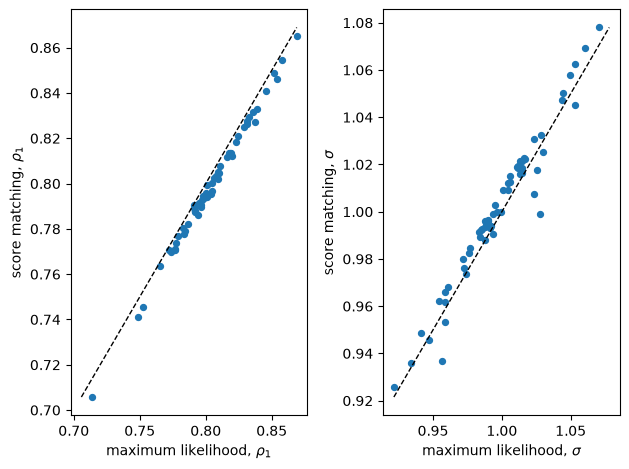

In [19]:
fig, axes = plt.subplots(1, 2)
for j, name in enumerate([r'$\rho_1$', r'$\sigma$']):
    axes[j].scatter(mle_draws[:, j], emm_draws[:, j], s=18)
    lo = min(mle_draws[:, j].min(), emm_draws[:, j].min())
    hi = max(mle_draws[:, j].max(), emm_draws[:, j].max())
    axes[j].plot([lo, hi], [lo, hi], 'k--', lw=1)
    axes[j].set_xlabel(f'maximum likelihood, {name}')
    axes[j].set_ylabel(f'score matching, {name}')
plt.tight_layout()
plt.show()

这两个估计量的标准差几乎相同。

两者的标准差都接近定理 2 给出的渐近值 $\sqrt{(1 - \rho_1^2)/T}$ 和 $\sigma / \sqrt{2T}$。

模拟因子 $1 + T/N$ 将得分匹配的值提高了大约 1%。

两个估计量在各次重复实验中的相关性非常接近 1，散点图紧贴 45 度线。

在每个样本中，这两个估计量几乎是同一个随机变量。

$\rho_1$ 的两个估计量的均值相差大约 0.005。

每次重复实验都共享冲击数组 `ε_mc`，因此它的模拟误差会一起移动全部 60 个得分匹配估计值。

下一个代码单元用三个其他的冲击数组重复进行 $\rho_1$ 的得分匹配估计。

In [20]:
gap = (emm_draws[:, 0] - mle_draws[:, 0]).mean()
print(f"shock array ε_mc:       mean gap in ρ1 = {gap:7.4f}")
for seed in (100, 101, 102):
    ε_alt = np.random.default_rng(seed).standard_normal(N_mc)
    ρ1_alt = np.array([emm_estimate(y_r, ε_alt)[0] for y_r in samples])
    gap = (ρ1_alt - mle_draws[:, 0]).mean()
    print(f"shock array seed {seed}:  mean gap in ρ1 = {gap:7.4f}")

shock array ε_mc:       mean gap in ρ1 = -0.0047
shock array seed 100:  mean gap in ρ1 =  0.0013
shock array seed 101:  mean gap in ρ1 =  0.0041
shock array seed 102:  mean gap in ρ1 =  0.0004


shock array seed 100:  mean gap in ρ1 =  0.0013


shock array seed 101:  mean gap in ρ1 =  0.0041


shock array seed 102:  mean gap in ρ1 =  0.0004


这个差距在不同的冲击数组之间改变符号，因此它是由模拟误差造成的。

```{solution-end}
```

```{exercise}
:label: gt_ex3

阶条件 $k_\theta \ge k_\rho$ 并不能保证可识别性。

Gallant 和 Tauchen 警告说，随机波动率模型混合过程的参数需要三阶和四阶矩信息，而高斯向量自回归的得分无法提供这些信息。

请研究他们的这一警告。

将随机波动率例子中的 GARCH 辅助模型替换为高斯 AR(2)，它有 $k_\theta = 3$ 个参数，对应 $k_\rho = 3$ 个结构参数，因此阶条件成立。

当 $k_\theta = k_\rho$ 时，该模型没有留下任何过度识别约束可供检验。

从若干不同的初始值出发最小化所得到的目标函数，并报告估计值及相应的目标函数值。

解释你的发现，并说明高斯 AR(2) 得分能确定 $(a, r_w, r_y)$ 的哪个函数。
```

```{solution-start} gt_ex3
:class: dropdown
```

In [21]:
θ_ar = ar2_qmle(y_sv)
S_ar = ar2_scores(θ_ar, y_sv)
W_ar = np.linalg.inv(S_ar.T @ S_ar / S_ar.shape[0])

def criterion_ar_score(u):
    if np.max(np.abs(u)) > 25:
        return 1e10
    ρ = to_ρ(u)
    if ρ[1] / np.sqrt(1 - ρ[0]**2) > 1.0:   # keep sd(w) where second moments stay reliable
        return 1e10
    m = ar2_scores(θ_ar, simulate_sv(ρ[0], ρ[1], ρ[2], z_sim, η_sim)).mean(axis=0)
    return float(m @ W_ar @ m)

def implied_var(ρ):
    "Unconditional variance of y implied by the structural parameters."
    a, r_w, r_y = ρ
    return r_y**2 * np.exp(2 * r_w**2 / (1 - a**2))

print(f"variance of the data = {y_sv.var():.3f}\n")
print(f"{'start a':>9}{'start r_w':>11}{'â':>9}{'r̂_w':>9}{'r̂_y':>9}"
      f"{'implied var':>13}{'criterion':>12}")
for a_s in [0.3, 0.6, 0.9]:
    for rw_s in [0.15, 0.30]:
        u_s = np.array([np.log(a_s / (1 - a_s)), np.log(rw_s), np.log(0.6)])
        rr = minimize(criterion_ar_score, u_s, method='Nelder-Mead',
                      options=dict(maxiter=600, xatol=1e-5, fatol=1e-14))
        ρ_s = to_ρ(rr.x)
        print(f"{a_s:>9.2f}{rw_s:>11.2f}{ρ_s[0]:>9.4f}{ρ_s[1]:>9.4f}"
              f"{ρ_s[2]:>9.4f}{implied_var(ρ_s):>13.3f}{rr.fun:>12.2e}")

bad = np.array([np.log(0.95/0.05), np.log(0.20), np.log(2.0)])
print(f"\ncriterion when the variance of y is badly wrong: {criterion_ar_score(bad):.2e}")

variance of the data = 0.544

  start a  start r_w        â     r̂_w     r̂_y  implied var   criterion
     0.30       0.15   0.4818   0.8250   0.3157        0.587    2.08e-03
     0.30       0.30   0.4818   0.8250   0.3157        0.587    2.08e-03
     0.60       0.15   0.4818   0.8250   0.3157        0.587    2.08e-03
     0.60       0.30   0.4818   0.8250   0.3157        0.587    2.08e-03
     0.90       0.15   0.8681   0.4965   0.2897        0.620    1.57e-03
     0.90       0.30   0.8643   0.5030   0.2891        0.618    1.56e-03

criterion when the variance of y is badly wrong: 6.95e+01


     0.30       0.15   0.4818   0.8250   0.3157        0.587    2.08e-03


     0.30       0.30   0.4818   0.8250   0.3157        0.587    2.08e-03


     0.60       0.15   0.4818   0.8250   0.3157        0.587    2.08e-03


     0.60       0.30   0.4818   0.8250   0.3157        0.587    2.08e-03


     0.90       0.15   0.8681   0.4965   0.2897        0.620    1.57e-03


     0.90       0.30   0.8643   0.5030   0.2891        0.618    1.56e-03

criterion when the variance of y is badly wrong: 6.95e+01


这些估计值在参数空间中四处游荡，而目标函数却停留在其最低点附近。

在这些差异巨大的参数向量各处，目标函数值都处于 $10^{-3}$ 量级，而当 $y$ 的方差严重错误时，目标函数值接近 70，这揭示出目标函数曲面上存在一个平坦的谷地。

在这个随机波动率模型中，$z_t$ 与波动率路径相互独立，因此 $y_t$ 在每一个 $(a, r_w, r_y)$ 处都是序列不相关的，尽管不是独立的。

记 $\gamma_j$ 为结构模型下 $y_t$ 的第 $j$ 阶自协方差。

当 $\gamma_1 = \gamma_2 = 0$ 时，高斯 AR(2) 得分的三个分量的期望为

$$
- \frac{\theta_1 \gamma_0}{\varsigma^2} , \qquad
- \frac{\theta_2 \gamma_0}{\varsigma^2} , \qquad
- \frac{1}{\varsigma} + \frac{(1 + \theta_1^2 + \theta_2^2) \, \gamma_0}{\varsigma^3} .
$$

这三者都只通过 $\gamma_0$（即方差）依赖于 $\rho$，

$$
\mathbb{V}(y_t) = r_y^2 \exp\!\left( \frac{2 r_w^2}{1 - a^2} \right) ,
$$

因此一个方程必须确定三个参数。

在总体中，任何使该表达式保持不变的 $(a, r_w, r_y)$ 都能同样好地拟合高斯 AR(2) 得分。

目标函数不会降至零。

数据的样本自相关并非恰好为零，因此 $\tilde\theta_1$ 和 $\tilde\theta_2$ 也不恰好为零，没有任何 $\gamma_0$ 值能使这三个期望都为零。

在有限的模拟中，模拟自协方差中的蒙特卡洛误差扰动了该谷地的底部，因此每一行所最小化的目标函数值略有不同。

表格证实了这一点：隐含方差聚集在数据方差附近，而三个参数本身却差异巨大。

代码对对数波动率过程的标准差 $r_w / \sqrt{1 - a^2}$ 设了边界，使搜索保持在模拟二阶矩可靠的区域内。

一个标准差非常大的对数波动率会使 $\exp(2 w_t)$ 变得非常重尾，以至于优化器可以仅靠利用蒙特卡洛误差就将模拟出的矩驱动至零。

厚尾和波动率聚集是四阶矩现象，而高斯自回归两者都记录不到。

前面使用的 GARCH 辅助模型通过其对数密度对 $u_t^2 / \sigma_t^2$ 的依赖性，能记录这两者，它能识别全部三个参数。

Gallant 和 Tauchen 推荐这种诊断方法：目标函数中的平坦区域预示着得分生成器对于该结构模型来说太小了。

```{solution-end}
```

```{exercise}
:label: gt_ex4

随机波动率例子设定 $a = 0.8$。

用 $a = 0.95$、$r_w = 0.2$ 和 $r_y = 0.65$ 重新运行它。

此时对数波动率的标准差为 $r_w / \sqrt{1 - a^2} = 0.64$，$y_t$ 的总体峰度约为 15.5。

a. 计算 GARCH 得分各分量在数据处的前三个自相关系数。

b. 用另外两种方法估计 $\mathcal{I}^0$。

第一种，使用 Gallant 和 Tauchen 的异方差与自相关一致估计。
它在外积的基础上加上得分在滞后 $\tau = 1, \ldots, \ell$ 处的样本自协方差，其中 $\ell = [n^{1/5}]$，权重为 Parzen 核 $w(\tau / \ell)$，其中

$$
w(x) =
\begin{cases}
1 - 6x^2 + 6x^3 & 0 \le x \le 1/2 , \\
2 (1 - x)^3 & 1/2 < x \le 1 .
\end{cases}
$$

第二种，在估计值 $\hat\rho_n$ 处，从结构模型中模拟出 300 个独立的长度为 $n$ 的数据集，在每个数据集中计算 $\sqrt{n}$ 乘以在 $\tilde\theta_n$ 处的平均 GARCH 得分，并求出跨数据集的协方差矩阵。

比较这三种估计的对角线元素。

c. 使用每一种 $\mathcal{I}^0$ 的估计重新估计 $\rho$，并比较定理 1 标准误。

定理 1 的公式 $\bigl[ M^\top W M \bigr]^{-1}$ 假设权重矩阵 $W$ 等于 $(\mathcal{I}^0)^{-1}$。

对于外积和 Parzen 估计量，还要计算三明治标准误

$$
\Bigl(1 + \frac{n}{N}\Bigr) \frac{1}{n}
\bigl( M^\top W M \bigr)^{-1} M^\top W \, \mathcal{I} \, W M \bigl( M^\top W M \bigr)^{-1} ,
$$

其中以 $\mathcal{I}^0$ 的模拟估计代替 $\mathcal{I}$。

d. 解释你的发现。
```

```{solution-start} gt_ex4
:class: dropdown
```

In [22]:
rng4 = np.random.default_rng(5)
a_4, r_w4, r_y4 = 0.95, 0.20, 0.65
y_4 = simulate_sv(a_4, r_w4, r_y4, rng4.standard_normal(T), rng4.standard_normal(T))

r_4 = minimize(garch_negll, θ_start, args=(y_4,), method='Nelder-Mead',
               options=dict(maxiter=8000, xatol=1e-8, fatol=1e-8))
θ_4 = r_4.x
S_4 = garch_scores(θ_4, y_4)
I_op = S_4.T @ S_4 / T

S_c = S_4 - S_4.mean(axis=0)
names = ['μ', 'ω', 'α', 'β']
print("autocorrelations of the GARCH score at lags 1, 2, 3")
for j, name in enumerate(names):
    ac = [np.corrcoef(S_c[:-k, j], S_c[k:, j])[0, 1] for k in (1, 2, 3)]
    print(f"{name:>4}: " + "".join(f"{x:8.3f}" for x in ac))

autocorrelations of the GARCH score at lags 1, 2, 3
   μ:    0.015  -0.020   0.015
   ω:    0.078   0.065   0.057
   α:    0.283   0.370   0.218
   β:    0.213   0.270   0.160


In [23]:
def parzen_hac(S):
    "Parzen-weighted estimate of I^0 with lag truncation [n^(1/5)]."
    n = S.shape[0]
    ℓ = int(n ** 0.2)
    V = S.T @ S / n
    for τ in range(1, ℓ + 1):
        x = τ / ℓ
        w = 1 - 6 * x**2 + 6 * x**3 if x <= 0.5 else 2 * (1 - x)**3
        Γ = S[τ:].T @ S[:-τ] / n
        V += w * (Γ + Γ.T)
    return V

z_4, η_4 = rng4.standard_normal(N), rng4.standard_normal(N)

def moments_4(ρ):
    return garch_scores(θ_4, simulate_sv(ρ[0], ρ[1], ρ[2], z_4, η_4)).mean(axis=0)

def estimate_4(W):
    "Score matching estimate and Theorem 1 standard errors for weighting matrix W."
    def crit(u):
        if np.max(np.abs(u)) > 25:
            return 1e10
        m = moments_4(to_ρ(u))
        return float(m @ W @ m)
    r_ = minimize(crit, u_0, method='Nelder-Mead',
                  options=dict(maxiter=400, xatol=1e-4, fatol=1e-10))
    ρ = to_ρ(r_.x)
    return ρ, std_errors(moments_4, ρ, W, T, N)

I_pz = parzen_hac(S_4)
ρ_op, se_op = estimate_4(np.linalg.inv(I_op))
ρ_pz, se_pz = estimate_4(np.linalg.inv(I_pz))

R_4 = 300
draws = np.empty((R_4, 4))
for i in range(R_4):
    y_i = simulate_sv(ρ_op[0], ρ_op[1], ρ_op[2],
                      rng4.standard_normal(T), rng4.standard_normal(T))
    draws[i] = np.sqrt(T) * garch_scores(θ_4, y_i).mean(axis=0)
I_sim = np.cov(draws.T)
ρ_sim, se_sim = estimate_4(np.linalg.inv(I_sim))

def sandwich_se(ρ, W, I):
    "Standard errors of the estimator with weighting matrix W when the score variance is I."
    M = jacobian(moments_4, ρ)
    A = np.linalg.inv(M.T @ W @ M)
    V = A @ M.T @ W @ I @ W @ M @ A * (1 + T / N) / T
    return np.sqrt(np.diag(V))

sw_op = sandwich_se(ρ_op, np.linalg.inv(I_op), I_sim)
sw_pz = sandwich_se(ρ_pz, np.linalg.inv(I_pz), I_sim)

print(f"{'diagonal of':24}" + "".join(f"{n:>9}" for n in names))
for label, I in [('outer product', I_op), ('Parzen', I_pz), ('simulated data sets', I_sim)]:
    print(f"{'  ' + label:24}" + "".join(f"{x:9.3f}" for x in np.diag(I)))

print(f"\n{'':24}{'a':>9}{'r_w':>9}{'r_y':>9}")
print(f"{'true values':24}{a_4:9.4f}{r_w4:9.4f}{r_y4:9.4f}")
for label, ρ, se, sw in [('outer product', ρ_op, se_op, sw_op),
                         ('Parzen', ρ_pz, se_pz, sw_pz),
                         ('simulated', ρ_sim, se_sim, None)]:
    print(f"{label + ': estimate':24}" + "".join(f"{x:9.4f}" for x in ρ))
    print(f"{'   std error':24}" + "".join(f"{x:9.4f}" for x in se))
    if sw is not None:
        print(f"{'   sandwich std error':24}" + "".join(f"{x:9.4f}" for x in sw))

diagonal of                     μ        ω        α        β
  outer product             3.059    0.045    1.182    1.701
  Parzen                    3.100    0.051    1.855    2.437
  simulated data sets       4.292    0.172    2.682    3.547

                                a      r_w      r_y
true values                0.9500   0.2000   0.6500
outer product: estimate    0.9453   0.1946   0.5791
   std error               0.0225   0.0264   0.0938
   sandwich std error      0.0335   0.0319   0.1356
Parzen: estimate           0.9452   0.1947   0.5785
   std error               0.0276   0.0282   0.1136
   sandwich std error      0.0336   0.0319   0.1351
simulated: estimate        0.9447   0.1956   0.5750
   std error               0.0342   0.0316   0.1331


$\alpha$ 和 $\beta$ 得分分量在滞后 1 到 3 处的自相关系数介于 0.16 和 0.37 之间。

对于这些数据来说，高斯 GARCH 模型是一个设定错误的得分生成器，其得分并非鞅差分。

外积遗漏了长期方差 $\mathcal{I}^0$ 所包含的自协方差。

对于 $\omega$、$\alpha$ 和 $\beta$ 分量，$\mathcal{I}^0$ 的模拟估计值是外积的两到四倍。

Parzen 估计只缩小了不到一半的这一差距。

在 $n = 2000$ 时，其滞后截断为 $\ell = 4$，在滞后 1、2、3 处的 Parzen 权重分别为 0.72、0.25 和 0.03，因此它舍弃了许多持续性的自协方差。

以外积作为 $W$，定理 1 的公式低估了 $a$ 和 $r_y$ 的标准误约三分之一。

Parzen 估计使这两个标准误提高了约五分之一。

外积和 Parzen 估计量的三明治标准误几乎等于使用 $\mathcal{I}^0$ 的模拟估计所得到的估计量的标准误。

这三个估计量几乎同样精确，并且估计值几乎没有变动。

劣质权重矩阵所造成的损害落在所报告的精度上。

在这里，估计量本身几乎没有任何损失。

模拟估计本身是不精确的。

GARCH 得分的方差取决于 $y_t$ 的八阶矩，而在这些参数值下这些矩非常巨大。

模拟估计还需要一个 $\rho$ 的初步估计，这是外积所不需要的要求。

Gallant 和 Tauchen 的建议解决了问题的根源：选择一个拟合良好的得分生成器。

{ref}`gt_choosing` 一节解释了原因：在级数展开中增加项数会使其得分趋向鞅差分，这样外积就是有效的。

```{solution-end}
```